# Proyecto: STATS19 #

Proyecto para el Módulo 1 del Diplomado de Métodos Estadísticos y Matemáticos para la Ciencia de Datos, Ed. 3 (Facultad de Ciencias, UNAM).

**Integrantes del equipo:**
- Guillermo Adolfo Méndez Roche
- Sofía Quetzalli González Robles
- [Nombre completo integrante 3]
- [Nombre completo integrante 4]
- [Nombre completo integrante 5]

**Fecha:** 22 de noviembre de 2026

## 1. Introducción ##

### 1.1. Fuente de los datos ###

El presente proyecto utiliza la base de datos **STATS19**, que recopila información oficial sobre siniestros viales ocurridos en Gran Bretaña. Los datos son reportados por 44 fuerzas policiales de Escocia, Gales e Inglaterra. Cabe mencionar que únicamente se registran siniestros que cumplen las siguientes tres condiciones:

1. Haber sucedido en la vía pública.

2. Haber causado lesiones o el fallecimiento de al menos una persona.

3. Haber llegado a conocimiento de la policía en un plazo máximo de 30 días después del siniestro.

**Procedencia y condiciones de uso.** La base de datos es publicada abiertamente por el Departamento de Transporte del Reino Unido (*DfT* por sus siglas en inglés) bajo la licencia **Open Government Licence v3.0 (OGL)**, la cual permite copiar, publicar, distribuir, adaptar y analizar la información libremente con fines académicos o analíticos, siempre que se cite la fuente oficial.

La documentación completa de los datos puede consultarse en [este enlace](https://www.gov.uk/government/statistical-data-sets/road-safety-open-data).

> **Advertencia.** El Departamento de Transporte del Reino Unido advierte que en STATS19 existe un subregistro importante de personas que sufren lesiones no mortales en siniestros viales, particularmente cuando se trata de lesiones leves. En particular, la ausencia de un registro de lesión no implica necesariamente que la persona haya resultado ilesa.

### 1.2. Datos de STATS19 ###

Como se mencionó anteriormente, STATS19 actualiza sus datos anualmente. No obstante, para el alcance de este proyecto, trabajaremos con los datos correspondientes a los años 2023, 2024 y 2025.

Para cada año, los datos se distribuyen en tres tablas:

- `collisions`: Cada fila representa un siniestro reportado. Contiene, entre otras variables, la fecha y hora del siniestro, así como el número de vehículos involucrados.

- `vehicles`: Cada fila representa un vehículo involucrado en un siniestro. Contiene variables como el tipo de vehículo, el sexo de quien conducía la unidad y el primer punto de impacto.

- `casualties`: Cada fila representa una persona lesionada o fallecida registrada como consecuencia de un siniestro. Contiene la clase de víctima (conductor, pasajero o peatón), la gravedad de sus lesiones y, cuando corresponde, la referencia del vehículo asociado.

#### 1.2.1. Guías y documentación ####

Algunas de las variables categóricas en STATS19 funcionan mediante códigos. Para interpretar dichos códigos, el Departamento de Transporte del Reino Unido proporciona una **guía oficial de decodificación de variables**, donde se desglosan los códigos asociados con ciertas variables y sus significados. 

La guía vigente al momento de la realización de este proyecto se encuentra en la carpeta [insertar carpeta] del repositorio. Adicionalmente, se incluyen las instrucciones oficiales vigentes de STATS20, que explican los criterios utilizados por las fuerzas policiales para registrar la información.

### 1.3. Identificadores y relaciones entre tablas ###

Para mantener un control de cuáles vehículos y víctimas pertenecen a cada siniestro, STATS19 implementa el uso de tres tipos de identificadores:

- En `collisions`, cada siniestro se identifica mediante un `collision_index`, que es una referencia alfanumérica única para cada siniestro.

- En `vehicles`, cada vehículo se identifica mediante la combinación de un `collision_index` y un `vehicle_reference`, que toma un valor único para cada vehículo dentro de un siniestro.

- En `casualties`, cada víctima se identifica mediante la combinación de `collision_index` y un `casualty_reference` (de manera análoga a como funcionan `collision_index` y `vehicle_reference` en el caso anterior).

  Cabe mencionar que en `casualties` también aparece la columna `vehicle_reference`, que permite vincular a las víctimas con un vehículo del siniestro, cuando corresponde.

Estos identificadores nos permitirán cruzar información de los siniestros, los vehículos involucrados y las víctimas registradas.

---

*Ejemplo.* A continuación incluimos un ejemplo ilustrativo de la tabla `vehicles`. Las filas del mismo color corresponden a vehículos registrados en un mismo siniestro.

Nótese que los valores de la columna `vehicle_type` son números enteros, pero la variable es **cualitativa nominal**, pues dichos códigos representan categorías de vehículos. En los tres años analizados, el código correspondiente a los automóviles es `9`.

In [1]:
# @title
from IPython.display import HTML, display

tabla_ejemplo_html = """
<table align="center" style="text-align: center; color: #22232F; border-collapse: collapse;">
    <tr style="background-color: #FFFFFF; border-bottom: 1px solid #CCC;">
        <th style="padding: 6px 12px;">collision_index</th>
        <th style="padding: 6px 12px;">vehicle_reference</th>
        <th style="padding: 6px 12px;">vehicle_type</th>
        <th style="padding: 6px 12px;">⋯</th>
    </tr>
    <tr style="background-color: #FFE699;">
        <td style="padding: 4px 12px;">2025010551786</td>
        <td style="padding: 4px 12px;">1</td>
        <td style="padding: 4px 12px;">3</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #FFE699;">
        <td style="padding: 4px 12px;">2025010551786</td>
        <td style="padding: 4px 12px;">2</td>
        <td style="padding: 4px 12px;">9</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #DCEAF5;">
        <td style="padding: 4px 12px;">2025010551795</td>
        <td style="padding: 4px 12px;">1</td>
        <td style="padding: 4px 12px;">9</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #DCEAF5;">
        <td style="padding: 4px 12px;">2025010551795</td>
        <td style="padding: 4px 12px;">2</td>
        <td style="padding: 4px 12px;">1</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #FFE9D6;">
        <td style="padding: 4px 12px;">2025010551794</td>
        <td style="padding: 4px 12px;">1</td>
        <td style="padding: 4px 12px;">9</td>
        <td style="padding: 4px 12px;">⋯</td>
    </tr>
    <tr style="background-color: #FFFFFF;">
        <td>⋮</td>
        <td>⋮</td>
        <td>⋮</td>
        <td>⋱</td>
    </tr>
</table>
"""
display(HTML(tabla_ejemplo_html))

collision_index,vehicle_reference,vehicle_type,⋯
2025010551786,1,3,⋯
2025010551786,2,9,⋯
2025010551795,1,9,⋯
2025010551795,2,1,⋯
2025010551794,1,9,⋯
⋮,⋮,⋮,⋱


### 1.4. Planteamiento del problema ###

#### 1.4.1. Preguntas conductoras ####

El análisis que realizamos en este proyecto parte de la siguiente idea:

> En siniestros con exactamente dos automóviles y conductores de distinto sexo, ¿cómo se comparan la presencia y la gravedad de las lesiones registradas de ambos conductores?

Más concretamente, responderemos las siguientes preguntas de investigación de carácter descriptivo, aunque con ciertas acotaciones que mencionaremos enseguida:

> *Primera pregunta.* Si solo uno de los conductores presenta lesiones registradas, ¿existe una tendencia consistente sobre si se trata del conductor o de la conductora?

> *Segunda pregunta.* Si tanto el conductor como la conductora presentan lesiones registradas de distinta gravedad, ¿existe una tendencia sobre cuál de los dos presenta las lesiones más graves?

#### 1.4.2. Algunas consideraciones metodológicas ####

1. *Sobre las condiciones del siniestro.*

   Es importante considerar que tanto la presencia como la gravedad de las lesiones podrían estar influenciadas por las condiciones físicas de cada colisión. Puesto que STATS19 no reporta variables como la masa de los vehículos o la velocidad al momento del impacto, restringiremos nuestro análisis a siniestros en los que ambos automóviles registraron un **primer punto de impacto frontal** (`first_point_of_impact == 1`). 
   
   Sin embargo, es importante aclarar que esto no significa que los automóviles hayan chocado entre sí: por ejemplo, podría suceder que ambos automóviles hayan esquivado algún objeto en la vía y a causa de ello se hayan estrellado, cada uno por separado, con algún muro. Asimismo, esta restricción no garantiza que ambos automóviles hayan experimentado impactos de magnitud similar, de modo que no representa el control total de las condiciones físicas del siniestro.

2. *Sobre la clasificación entre la gravedad de las lesiones.*

   En la tabla `casualties`, donde cada registro se corresponde con una víctima, la columna `casualty_severity` es una variable categórica ordinal que describe el grado de gravedad de las lesiones de la víctima en una escala de tres severidades: mortal, grave y leve, codificadas como `1`, `2` y `3`, respectivamente.

   Respecto a dicha variable, el Departamento de Transporte del Reino Unido declara que existen diferencias en la distinción de lesiones leves y graves entre fuerzas policiales. En este sentido, analizar el comportamiento de dicha variable en áreas que abarquen distintas zonas policiales requiere de consideraciones adicionales contempladas en la documentación de STATS19.

   Para nuestra segunda pregunta conductora, comparamos la gravedad de las lesiones de dos conductores involucrados en un mismo siniestro. Esta comparación reduce la influencia de las diferencias de criterios entre fuerzas policiales, aunque no elimina posibles errores o inconsistencias en la clasificación de las lesiones dentro del mismo siniestro.

## 2. Carga y exploración inicial de datos ##

### 2.1. Importación de paquetes y carga de datos ###

El siguiente bloque de código importa los paquetes que utilizaremos a lo largo de este proyecto:

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Carpeta para exportar resultados y figuras del repositorio

os.makedirs("resultados", exist_ok=True)

Por otro lado, cargamos los datos de STATS19 para los años 2023, 2024 y 2025. Nótese que se cargan tres tablas por año: una tabla de siniestros, una de vehículos y una de víctimas para cada año, dando un total de nueve tablas.

In [3]:
# En su momento, estos datos se van a cargar desde una carpeta local (que el usuario descargará desde el repositiorio)

# Esta columna hay que modificarla cuando ya tengamos el repositorio y su estructura

# Datos de 2023

collisions_2023 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-collision-2023.csv",
    low_memory=False
)

vehicles_2023 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-vehicle-2023.csv",
    low_memory=False
)

casualties_2023 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-casualty-2023.csv",
    low_memory=False
)

# Datos de 2024

collisions_2024 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-collision-2024.csv",
    low_memory=False
)

vehicles_2024 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-vehicle-2024.csv",
    low_memory=False
)

casualties_2024 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-casualty-2024.csv",
    low_memory=False
)

# Datos de 2025

collisions_2025 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-collision-2025.csv",
    low_memory=False
)

vehicles_2025 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-vehicle-2025.csv",
    low_memory=False
)

casualties_2025 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-casualty-2025.csv",
    low_memory=False
)

print("Datos de STATS19 cargados correctamente.")

Datos de STATS19 cargados correctamente.


Como estamos trabajando con datos de tres años distintos, es conveniente dejar clara la estructura que seguiremos. Dicha estructura estará dada en un diccionario:

In [4]:
# En este diccionario guardamos la información de STATS19 para cada año #

datos = {
    2023: {
        "collisions": collisions_2023,
        "vehicles": vehicles_2023,
        "casualties": casualties_2023
    },
    2024: {
        "collisions": collisions_2024,
        "vehicles": vehicles_2024,
        "casualties": casualties_2024
    },
    2025: {
        "collisions": collisions_2025,
        "vehicles": vehicles_2025,
        "casualties": casualties_2025
    }
}

Por ejemplo, si queremos visualizar las primeras tres filas de siniestros de 2025 podemos ejecutar el siguiente bloque de código:

In [5]:
datos[2025]["collisions"].head(3)

,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202517M101925,2025,17M101925,447673.0,519279.0,-1.26420,54.56650,17,3,1,...,-1,0,1,1,2,E01012014,3,1,0.0,1.0
1,202517L205225,2025,17L205225,454611.0,518597.0,-1.15704,54.55967,17,3,2,...,-1,0,1,1,2,E01012173,3,1,0.0,1.0
2,2025070971700,2025,070971700,354476.0,382656.0,-2.68516,53.33884,7,3,2,...,-1,0,2,1,2,E01012444,3,1,0.0,1.0


O bien, si queremos conocer el número de vehículos asociados con algún siniestro durante ese mismo año, podemos ejecutar la siguiente celda:

In [6]:
datos[2025]["vehicles"].shape[0]

183948

### 2.2. Exploración inicial de los datos ###

Comenzaremos por examinar las dimensiones de las nueve tablas originales, identificando el número de filas y columnas de cada una.

In [7]:
resumen = []

for año, tablas_anuales in datos.items():
    for título, tabla in tablas_anuales.items():
        resumen.append({
            "Año": año,
            "Tabla": título,
            "Filas": tabla.shape[0],
            "Columnas": tabla.shape[1]
        })

resumen = pd.DataFrame(resumen)

for año, grupo in resumen.groupby("Año"):
    print(f"Tablas del año {año}:")
    display(grupo[["Tabla", "Filas", "Columnas"]].reset_index(drop=True))

Tablas del año 2023:


,Tabla,Filas,Columnas
0,collisions,104258,44
1,vehicles,189815,32
2,casualties,132977,24


Tablas del año 2024:


,Tabla,Filas,Columnas
0,collisions,100927,44
1,vehicles,183514,32
2,casualties,128272,24


Tablas del año 2025:


,Tabla,Filas,Columnas
0,collisions,101525,44
1,vehicles,183948,32
2,casualties,127883,24


### 2.3. Selección y verificación de variables ###

Comenzamos por identificar cada una de las variables que serán necesarias para realizar nuestro análisis.

In [8]:
# De la tabla de siniestros solo nos interesan:

# Su identificador
# El número de vehículos involucrados

variables_siniestros = ["collision_index",
                        "number_of_vehicles"
                        ]

# De la tabla de vehículos solo nos interesan:

# El identificador del siniestro al que corresponden
# El número de referencia dentro del siniestro
# El tipo de vehículo
# El sexo del conductor
# El primer punto de impacto

variables_vehículos = ["collision_index",
                       "vehicle_reference",
                       "vehicle_type",
                       "sex_of_driver",
                       "first_point_of_impact"
                       ]

# De la tabla de víctimas solo nos interesan:

# El identificador del siniestro al que corresponden
# El número de referencia de la víctima dentro del siniestro
# El número de referencia del vehículo asociado
# La clase de víctima
# La gravedad de las lesiones

variables_víctimas = ["collision_index",
                      "casualty_reference",
                      "vehicle_reference",
                      "casualty_class",
                      "casualty_severity"]

# Guardamos las variables que nos interesan en un diccionario

variables = {"siniestros": variables_siniestros,
             "vehículos": variables_vehículos,
             "víctimas": variables_víctimas
            }

#### 2.3.1. Presencia de las variables en los tres años ####

El siguiente paso será verificar que las variables de interés estén presentes en las tablas de los tres años a analizar (esto porque, en principio, la estructura de las tablas de STATS19 puede variar año con año).

El siguiente bloque de código define y ejecuta una función que toma un `int` (el año) como argumento y verifica que las variables de interés aparezcan en las tablas correspondientes a dicho año. En caso de no encontrar alguna, se obtiene un `AssertionError` y un mensaje con más información al respecto.

In [9]:
def verificar_variables(año: int) -> None:

    """Verifica que las variables de interés existan en las tablas del año indicado."""

    siniestros = datos[año]["collisions"]

    vehículos = datos[año]["vehicles"]

    víctimas = datos[año]["casualties"]

    assert set(variables["siniestros"]).issubset(siniestros.columns), (
        f"Faltan columnas en collisions ({año})."
    )

    assert set(variables["vehículos"]).issubset(vehículos.columns), (
        f"Faltan columnas en vehicles ({año})."
    )

    assert set(variables["víctimas"]).issubset(víctimas.columns), (
        f"Faltan columnas en casualties ({año})."
    )

for año in datos.keys():
    verificar_variables(año)

print("Verificación exitosa: todas las variables seleccionadas existen en 2023, 2024 y 2025.")

Verificación exitosa: todas las variables seleccionadas existen en 2023, 2024 y 2025.


### 2.4. Calidad de los datos

Es importante considerar que, aun cuando todas las variables de interés estén presentes en los tres años, es posible que haya registros faltantes o datos erróneos en las columnas, lo cual podría afectar nuestro análisis.

#### 2.4.1. Identificadores repetidos ####

Recordemos que en la tabla `collisions` cada siniestro está identificado mediante un identificador `collision_index` (que, en principio, debe ser único).

A su vez, en la tabla `vehicles`, cada vehículo se identifica con una combinación de un `collision_index` (del siniestro al que corresponde) y una referencia del vehículo dentro de dicho siniestro (`vehicle_reference`).

Lo análogo sucede en la tabla de `casualties`, donde cada víctima está identificada por una combinación de un `collision_index` y una referencia de la víctima dentro del siniestro correspondiente (`casualty_reference`).

El siguiente bloque de código recorre cada uno de estos tipos de identificadores y verifica que no existan identificadores repetidos en cada una de las tablas, para cada año.

In [10]:
for año in datos.keys():

    siniestros = datos[año]["collisions"]
    vehículos = datos[año]["vehicles"]
    víctimas = datos[año]["casualties"]

    print(f"Unicidad de identificadores para el año {año}\n")

    print(f"{'Identificadores de siniestros duplicados:':<45}{siniestros['collision_index'].duplicated().sum()}")
    print(f"{'Identificadores de vehículos duplicados:':<45}{vehículos.duplicated(['collision_index', 'vehicle_reference']).sum()}")
    print(f"{'Identificadores de víctimas duplicados:':<45}{víctimas.duplicated(['collision_index', 'casualty_reference']).sum()}\n")



Unicidad de identificadores para el año 2023

Identificadores de siniestros duplicados:    0
Identificadores de vehículos duplicados:     0
Identificadores de víctimas duplicados:      0

Unicidad de identificadores para el año 2024

Identificadores de siniestros duplicados:    0
Identificadores de vehículos duplicados:     0
Identificadores de víctimas duplicados:      0

Unicidad de identificadores para el año 2025

Identificadores de siniestros duplicados:    0
Identificadores de vehículos duplicados:     0
Identificadores de víctimas duplicados:      0



#### 2.4.2. Consistencia en el número de vehículos ####

Recordemos que, en la tabla `collisions`, la variable `number_of_vehicles` indica el número de vehículos involucrados en cada siniestro. Por su parte, la tabla `vehicles` contiene un registro por cada vehículo asociado a un siniestro, como se ilustró en la sección 1.3. En principio, debería suceder que:

$$ \text{no. de vehículos declarados para un siniestro} = \text{no. de filas de }\mathtt{vehicles}\text{ correspondientes a ese siniestro} $$

En ciertas partes del código usaremos el valor de `number_of_vehicles` para hacer operaciones con el número de vehículos involucrados en cierto siniestro, mientras que en otras será más fácil utilizar el número de filas en `vehicles`. Así pues, verificaremos que ambas cantidades coincidan para cada siniestro; solo posteriormente podremos utilizarlas indistintamente en nuestro análisis.

Para ello, agruparemos en `vehicles` según `collision_index` y contaremos el tamaño de cada grupo mediante el método `size`, lo cual arrojará el número de filas correspondientes: ese es el número que compararemos con `number_of_vehicles`.

In [11]:
resumen = []

for año in datos:

    siniestros = datos[año]["collisions"]
    vehículos = datos[año]["vehicles"]

    # Número de vehículos registrados por cada siniestro
    número_de_filas = vehículos.groupby("collision_index").size()

    # Número de vehículos declarados en collisions
    número_declarado = siniestros.set_index("collision_index")["number_of_vehicles"]

    # Comparamos ambas series
    discrepancias = número_de_filas.ne(número_declarado)

    resumen.append({"Año": año,
                    "Discrepancias": discrepancias.sum()})

display(pd.DataFrame(resumen).style.hide(axis="index"))

Año,Discrepancias
2023,0
2024,0
2025,0


#### 2.4.3. Calidad de las variables principales: sexo y gravedad de lesiones ####

Nuestras preguntas conductoras tienen que ver con el sexo de los conductores y la gravedad de sus lesiones, en caso de haberlas, así que conviene hacer una exploración preliminar de dichas variables para determinar si es viable hacer el análisis que proponemos.

##### 2.4.3.1. Sexo del conductor #####

Con respecto al sexo de los conductores, está codificado en la variable `sex_of_driver` de la tabla `vehicles`. Según la documentación oficial de STATS20, funciona de la siguiente manera:

- Para conductores cuyo sexo fue identificado como *masculino*, el valor de la columna `sex_of_driver` es igual a `1`.

- Para conductores cuyo sexo fue identificado como *femenino*, el valor de la columna `sex_of_driver` es igual a `2`.

- El código `3` corresponde a los conductores con *sexo desconocido*. 

  Según lo descrito en STATS20, se debe capturar este código cuando el conductor no se detuvo en la escena, o bien, cuando la policía no tuvo éxito localizando a quien conducía el vehículo. 
  
  Así pues, si bien deberemos filtrar estos registros para responder nuestras dos preguntas conductoras, debemos tener en mente que este código no indica (al menos conceptualmente) una ausencia de información debida a errores en el proceso de captura; puede aportar información importante sobre las características de un siniestro. 

  Por lo tanto, no podemos asumir que estos valores se distribuyen de manera aleatoria en los registros: las condiciones de un siniestro pueden influir en la presencia de este dato en los registros correspondientes.

Para examinar la distribución porcentual de los valores que aparecen en la columna `sex_of_driver` en cada año, se puede ejecutar la siguiente celda:

In [12]:
porcentajes = {}

for año, datos_anuales in datos.items():

    sexo = datos_anuales["vehicles"]["sex_of_driver"]

    porcentajes[año] = sexo.value_counts(normalize=True,
                                         dropna=False) * 100

tabla = pd.DataFrame(porcentajes).fillna(0).round(2)

orden = [1, 2, 3] + [valor for valor in tabla.index if valor not in [1, 2, 3]]

tabla = tabla.reindex(orden)

display(tabla.
        reset_index().
        style.
        hide(axis="index").
        format("{:.2f}%", subset=tabla.columns)
)

sex_of_driver,2023,2024,2025
1,60.97%,60.66%,61.11%
2,25.57%,25.57%,25.58%
3,13.46%,11.85%,10.97%
-1,0.00%,1.93%,2.34%


Es pertinente hacer algunas observaciones al respecto:

1. En los tres años, **aproximadamente el 60%** de los registros totales corresponden a conductores cuyo sexo fue identificado como **masculino**, en contraste con los conductores cuyo sexo fue identificado como **femenino**, que representan **alrededor del 25%** de los registros totales para los tres años. 

   Esto hace ver que, **alrededor del 70% de los registros con sexo conocido corresponden a hombres**. No obstante, es importante observar que la población que analizaremos en nuestras dos preguntas conductoras corresponde a siniestros donde un conductor fue hombre y el otro mujer, *cada siniestro aporta un conductor de cada sexo*, eliminando este desequilibrio numérico al momento de hacer comparaciones. 

2. En los tres años aparecen registros bajo el código `3`, cuyo significado oficial fue explicado más arriba. La proporción de estos registros disminuye del 13.46% en 2023 al 11.85% en 2024 y al 10.97% en 2025.

   Sin embargo, observamos que el código `-1`, ausente en 2023, aparece en el **1.93% de los registros de 2024 y el 2.34% de los de 2025**. Si agrupamos ambos códigos, encontramos que la proporción de registros cuyo sexo desconocemos **se mantiene alrededor del 13% durante los tres años**. Por tanto, no podemos concluir que haya mejorado la disponibilidad de esta información, y queda pendiente investigar por qué el código `-1` comienza a aparecer en 2024.

##### 2.4.3.2. Gravedad de las lesiones #####


Otra variable que nos interesa es `casualty_severity`, de la tabla `casualties`, que codifica la gravedad de las lesiones de una víctima según la siguiente escala:

- Si las lesiones son mortales, se codifican con el código `1`

- Si las lesiones son graves, se codifican con el código `2`

- Si las lesiones son leves, se codifican con el código `3`

Veamos si en verdad aparecen solo estos códigos y cómo se distribuyen, para cada uno de los años que estamos estudiando:

In [13]:
frecuencias = {}

for año, datos_anuales in datos.items():

    víctimas = datos_anuales["casualties"]

    frecuencias[año] = víctimas["casualty_severity"].value_counts(dropna=False)

tabla = pd.DataFrame(frecuencias).fillna(0).astype(int).reset_index().sort_values("casualty_severity")

display(tabla.style.hide(axis="index"))

casualty_severity,2023,2024,2025
1,1624,1602,1538
2,26030,26040,27758
3,105323,100630,98587


En este caso, no tenemos valores faltantes: todos los registros de la columna `casualty_severity` se distribuyen en las categorías de gravedad declaradas en la documentación de STATS19. Para ver lo anterior en porcentajes, podemos ejecutar el siguiente bloque de código:

In [14]:
porcentajes = {}

for año, datos_anuales in datos.items():

    víctimas = datos_anuales["casualties"]

    gravedad = víctimas["casualty_severity"].replace({
        1: "Mortal",
        2: "Grave",
        3: "Leve"
    })

    porcentajes[año] = gravedad.value_counts(
        normalize=True, dropna=False
    ) * 100

tabla = pd.DataFrame(porcentajes).fillna(0).round(2)

tabla = tabla.reindex(["Mortal", "Grave", "Leve"])

display(
    tabla.reset_index().style
    .hide(axis="index")
    .format("{:.2f}%", subset=tabla.columns)
)

casualty_severity,2023,2024,2025
Mortal,1.22%,1.25%,1.20%
Grave,19.57%,20.30%,21.71%
Leve,79.20%,78.45%,77.09%


Esto nos dice que, en la segunda de nuestras variables principales, todos los registros se distribuyen sobre alguna de las tres categorías cuyo significado conocemos. 

## 3. Construcción de la población de estudio ###

En esta sección comenzamos a analizar el problema de transformación más importante del proyecto. Recordemos que nuestra población de estudio está formada por el conjunto de siniestros de STATS19 entre 2023 y 2025 que satisfacen las siguientes condiciones:

- Tener exactamente dos vehículos declarados en `number_of_vehicles`.

- Ambos vehículos deben ser automóviles.

- Los conductores deben ser de distintos sexos.

- Ambos vehículos deben tener registrado el frente como primer punto de impacto.

El filtrado consistirá en tres etapas: 

1. Seleccionaremos, de entre todos los siniestros de STATS19, aquellos en los que solo se hayan registrado dos vehículos involucrados, siendo ambos automóviles. 

2. Seleccionaremos, de los siniestros que sobrevivieron al primer filtro, aquellos en los que los conductores eran de sexos opuestos.

3. Seleccionaremos, de entre los siniestros que sobrevivieron al segundo filtro, aquellos en los que el primer punto de impacto de ambos vehículos fue frontal.

### 3.1. Selección de siniestros con exactamente dos automóviles ###

En esta sección identificaremos los siniestros que cumplen las dos primeras condiciones y guardaremos sus identificadores en un diccionario, sin modificar las tablas originales. Posteriormente utilizaremos estos identificadores para construir nuestra población de estudio.

In [15]:
# Por cada año, vamos a rescatar los identificadores que correspondan a siniestros de dos vehículos, ambos automóviles

# Por ahora, comenzamos con tres listas vacías, una por cada año

identificadores_dos_autos = {2023:[],
                             2024:[],
                             2025:[]}

resumen = {}

for año in datos:

    siniestros = datos[año]["collisions"]
    vehículos = datos[año]["vehicles"]

    # Seleccionamos únicamente los automóviles.

    automóviles = vehículos[vehículos["vehicle_type"] == 9]

    # Contamos los automóviles por siniestro.

    número_de_autos = automóviles.groupby("collision_index").size()

    # Número de vehículos declarados en collisions.

    número_de_vehículos_declarados = siniestros.set_index("collision_index")["number_of_vehicles"]

    # Seleccionamos los siniestros con exactamente dos vehículos, ambos automóviles

    # ¡Ojo! En esta parte cobra importancia la comprobación de consistencia en el número de vehículos (sección 2.4.2)

    # Como comprobamos que ambos conteos coinciden en nuestros datos, podemos compararlos para seleccionar los siniestros de interés.

    condición = (número_de_autos.eq(número_de_vehículos_declarados) &
                 número_de_vehículos_declarados.eq(2))

    identificadores_dos_autos[año] = condición.loc[condición == True].index.tolist()

    resumen[año] = {
    "Siniestros": len(siniestros),
    "Siniestros de dos automóviles": len(identificadores_dos_autos[año]),
    "Siniestros seleccionados (%)": (
        len(identificadores_dos_autos[año]) / len(siniestros) * 100
    )
}

display(
    pd.DataFrame.from_dict(resumen, orient="index")
    .rename_axis("Año")
    .reset_index()
    .style
    .hide(axis="index")
    .format({"Siniestros seleccionados (%)": "{:.2f}%"})
)

Año,Siniestros,Siniestros de dos automóviles,Siniestros seleccionados (%)
2023,104258,26157,25.09%
2024,100927,25429,25.20%
2025,101525,24315,23.95%


### 3.2. Selección de las parejas hombre-mujer ###

Puesto que la variable `sex_of_driver` se encuentra en la tabla `vehicles`, recuperaremos los vehículos correspondientes a los siniestros seleccionados en la sección anterior y examinaremos el sexo registrado de sus conductores.

Una vez hecho lo anterior, procederemos a seleccionar los siniestros en los que uno de los automóviles era conducido por un hombre y el otro por una mujer.

Cabe mencionar que decidimos no imputar valores a los registros cuyo sexo es desconocido o no puede clasificarse como masculino o femenino, pues no contamos con información suficiente para asignarles un valor confiable. Tampoco eliminaremos dichos registros de las tablas originales; es decir, únicamente los excluiremos al construir nuestra población de estudio.

In [16]:
# Seleccionamos los siniestros de dos automóviles en los cuales los conductores eran de sexos opuestos.

identificadores_hombre_mujer = {2023:[],
                                2024:[],
                                2025:[]}

tabla_resumen = {}

for año in datos:

    vehículos = datos[año]["vehicles"]

    # Recuperamos los vehículos de los siniestros seleccionados en 3.1.

    automóviles = vehículos.loc[
        vehículos["collision_index"].isin(identificadores_dos_autos[año])
    ].copy()

    # Creamos las columnas hombre y mujer.

    automóviles["hombre"] = automóviles["sex_of_driver"] == 1

    automóviles["mujer"] = automóviles["sex_of_driver"] == 2

    # Contamos las características por siniestro.

    resumen = automóviles.groupby("collision_index").agg(
        hombres=("hombre", "sum"),
        mujeres=("mujer", "sum")
    )

    # Seleccionamos las parejas que cumplen ambas condiciones.

    condición = (
        resumen["hombres"].eq(1) &
        resumen["mujeres"].eq(1)
    )

    identificadores_hombre_mujer[año] = resumen.loc[
        condición
    ].index.tolist()

    tabla_resumen[año] = {
        "Siniestros de dos automóviles": len(identificadores_dos_autos[año]),
        "Siniestros hombre-mujer": len(identificadores_hombre_mujer[año]),
        "Siniestros seleccionados (%)": (
            len(identificadores_hombre_mujer[año]) / len(identificadores_dos_autos[año]) * 100
        )
    }

tabla = (
    pd.DataFrame.from_dict(tabla_resumen, orient="index")
    .rename_axis("Año")
    .reset_index()
)

display(
    tabla.style
    .hide(axis="index")
    .format({"Siniestros seleccionados (%)": "{:.2f}%"})
)

Año,Siniestros de dos automóviles,Siniestros hombre-mujer,Siniestros seleccionados (%)
2023,26157,9825,37.56%
2024,25429,9453,37.17%
2025,24315,9082,37.35%


### 3.3. Selección de los siniestros con primer punto de impacto frontal registrado en ambos vehículos

In [17]:
# Seleccionamos los siniestros hombre-mujer en los que ambos automóviles registran el frente como primer punto de impacto

población_final = {2023:[],
                   2024:[],
                   2025:[]}

tabla_resumen = {}

for año in datos:

    vehículos = datos[año]["vehicles"]

    # Recuperamos los vehículos de los siniestros seleccionados en el filtro anterior.

    automóviles = vehículos.loc[
        vehículos["collision_index"].isin(identificadores_hombre_mujer[año])
    ].copy()

    # Creamos la columna impacto_frontal.

    automóviles["impacto_frontal"] = automóviles["first_point_of_impact"] == 1

    # Contamos las características por siniestro.

    resumen = automóviles.groupby("collision_index").agg(
        impactos_frontales=("impacto_frontal", "sum")
    )

    # Seleccionamos las parejas que cumplen la condición.

    condición = resumen["impactos_frontales"].eq(2)

    población_final[año] = resumen.loc[
        condición
    ].index.tolist()

    tabla_resumen[año] = {
        "Siniestros hombre-mujer": len(identificadores_hombre_mujer[año]),
        "Ambos impactos frontales": len(población_final[año]),
        "Siniestros seleccionados (%)": (
            len(población_final[año]) / len(identificadores_hombre_mujer[año]) * 100
        )
    }

tabla = (
    pd.DataFrame.from_dict(tabla_resumen, orient="index")
    .rename_axis("Año")
    .reset_index()
)

display(
    tabla.style
    .hide(axis="index")
    .format({"Siniestros seleccionados (%)": "{:.2f}%"})
)

Año,Siniestros hombre-mujer,Ambos impactos frontales,Siniestros seleccionados (%)
2023,9825,2202,22.41%
2024,9453,2197,23.24%
2025,9082,2078,22.88%


### 3.4. Construcción del diccionario `análisis`

El objetivo de esta sección es crear un nuevo diccionario que tenga la misma estructura que `datos`, pero contenga únicamente los registros asociados a los siniestros de nuestra población de estudio: aquellos con exactamente dos vehículos, ambos automóviles, conducidos por un hombre y una mujer, y en los que ambos vehículos tienen registrado el frente como primer punto de impacto.

A dicho diccionario le llamaremos `análisis`.

In [18]:
análisis = {}

for año, datos_anuales in datos.items():

    identificadores = población_final[año]

    siniestros = datos_anuales["collisions"]
    vehículos = datos_anuales["vehicles"]
    víctimas = datos_anuales["casualties"]

    # Identificamos los registros que pertenecen a nuestra población de estudio.

    condición_siniestros = siniestros["collision_index"].isin(identificadores)
    condición_vehículos = vehículos["collision_index"].isin(identificadores)
    condición_víctimas = víctimas["collision_index"].isin(identificadores)

    # Filtramos las tres tablas.

    siniestros = siniestros.loc[condición_siniestros].copy()
    vehículos = vehículos.loc[condición_vehículos].copy()
    víctimas = víctimas.loc[condición_víctimas].copy()

    # Ordenamos los registros por siniestro.

    # Ordenamos los registros para que los dos vehículos involucrados aparezcan consecutivamente

    siniestros = siniestros.sort_values("collision_index")

    vehículos = vehículos.sort_values(
    ["collision_index", "vehicle_reference"]
    )

    víctimas = víctimas.sort_values(
    ["collision_index", "casualty_reference"]
    )

    # Conservamos únicamente las variables seleccionadas en la sección 2.3.

    siniestros = siniestros[variables_siniestros]

    vehículos = vehículos[variables_vehículos]

    víctimas = víctimas[variables_víctimas]

    # Construimos el diccionario con las tablas filtradas.

    análisis[año] = {
        "collisions": siniestros,
        "vehicles": vehículos,
        "casualties": víctimas
    }


## 4. Análisis de las lesiones registradas en cada pareja

Hasta ahora solo hemos construido los siniestros que conforman nuestra población de estudio, sin tomar en cuenta información sobre las posibles lesiones de los conductores.

Así pues, en esta sección esta sección incorporaremos dicha información y, posteriormente, responderemos nuestras dos preguntas conductoras mediante un análisis descriptivo de los resultados.

### 4.1. Decisión de transformación: incorporación de las lesiones de los conductores ###

Para responder a las dos preguntas conductoras debemos conocer, para cada siniestro en nuestra población, si los conductores registran lesiones; sin embargo, hasta ahora no hemos considerado esa información. Nos encontramos entonces con el siguiente problema:

**Problema.** Debemos decidir dónde guardar la información que relacione conductores con su presencia de lesiones y gravedad de las mismas.

**Cómo lo abordamos.** Afortunadamente, podemos resolver este problema con las herramientas que hemos construido hasta ahora; vamos a aprovechar la estructura que tenemos en la tabla `vehicles`, en la cual aparecen dos filas por cada siniestro.

In [19]:
display(análisis[2025]["vehicles"].head(6))

,collision_index,vehicle_reference,vehicle_type,sex_of_driver,first_point_of_impact
99648,2025010551987,1,9,2,1
56013,2025010551987,2,9,1,1
173446,2025010553488,1,9,1,1
4694,2025010553488,2,9,2,1
106931,2025010553648,1,9,2,1
78328,2025010553648,2,9,1,1


Conceptualmente, la tabla tiene una fila por cada vehículo, pero también podemos interpretar lo anterior como una fila por cada conductor. Así pues,  podemos agregar a esta tabla la información de las lesiones de los conductores, en caso de haberlas, que rescataremos de la tabla `casualties`. 

En concreto vamos a crear dos nuevas columnas en la tabla de arriba:

- `lesión_registrada`.

  Sus entradas serán valores booleanos. Su valor será `True` si el conductor aparece listado en la tabla de víctimas y `False` en el caso contrario.

- `casualty_severity`.

  Esta columna ya existe en `casualties`, así que solo la agregaremos mediante el método `merge`. Es posible que un conductor no tenga lesiones registradas; en tal caso, la unión le asignará un `NaN`.

**Consecuencias para nuestros datos o resultados.** En este caso, si logramos hacer nuestro cometido de manera ordenada, las consecuencias serán beneficiosas: tendremos una tabla de vehículos que, en el fondo, estará guardando la información de nuestra población de estudio. Es decir, a partir de este punto, la tabla `vehicles` será nuestra principal fuente de información para dar respuesta a las preguntas conductoras.

In [20]:
for año, datos_anuales in análisis.items():

    víctimas = datos_anuales["casualties"]
    vehículos = datos_anuales["vehicles"]

    # Seleccionamos los registros de víctimas que a su vez son conductores. 
    # Es decir, en la tabla de víctimas, localizamos a aquellas clasificadas como conductores.

    conductores_lesionados = víctimas.loc[víctimas["casualty_class"] == 1]

    # Conservamos únicamente las columnas necesarias.

    variables_conductores = ["collision_index","vehicle_reference","casualty_severity"]

    conductores_lesionados = conductores_lesionados[variables_conductores].copy()

    # Agregamos a `vehículos` la información de los conductores mediante una unión izquierda

    vehículos = vehículos.merge(
        conductores_lesionados,
        on=["collision_index", "vehicle_reference"],
        how="left",
        validate="one_to_one"
    )

    # Sanity check: verificamos que cada conductor lesionado haya encontrado su correspondencia en la tabla de vehículos

    assert vehículos["casualty_severity"].notna().sum() == len(conductores_lesionados)

    # Creamos una columna que indica si existe una lesión registrada.

    vehículos["lesión_registrada"] = vehículos["casualty_severity"].notna()

    análisis[año]["vehicles"] = vehículos

Con esto terminamos la incorporación de las columnas. Podemos ver cómo quedó la tabla de vehículos para, por ejemplo, el año 2025 ejecutando el siguiente bloque de código:

In [21]:
display(análisis[2025]["vehicles"].head(6))

,collision_index,vehicle_reference,vehicle_type,sex_of_driver,first_point_of_impact,casualty_severity,lesión_registrada
0,2025010551987,1,9,2,1,2.0,True
1,2025010551987,2,9,1,1,NaN,False
2,2025010553488,1,9,1,1,3.0,True
3,2025010553488,2,9,2,1,NaN,False
4,2025010553648,1,9,2,1,3.0,True
5,2025010553648,2,9,1,1,3.0,True


### 4.2. Siniestros con un solo conductor lesionado ###


En esta sección usaremos la información obtenida hasta ahora para responder nuestra primera pregunta conductora:

*"Si solo uno de los conductores presenta lesiones registradas, ¿hay una tendencia sobre si se trata del conductor o la conductora?"*


In [22]:
# Para cada año, contaremos el porcentaje de siniestros donde el único conductor lesionado fue hombre o mujer

# Los guardaremos en este DataFrame de pandas:

porcentajes_un_lesionado = pd.DataFrame({"Año":[2023,2024,2025],
                                         "Solo el conductor registra lesiones (%)":[None,None,None],
                                         "Solo la conductora registra lesiones (%)":[None,None,None]})

# Vamos a recorrer cada uno de los años y obtener los porcentajes

for año, datos_anuales in análisis.items():

    # El primer paso será identificar los siniestros con un solo conductor lesionado

    identificadores = []

    # Cargamos nuestra tabla de vehículos

    vehículos = análisis[año]["vehicles"]
    
    # El código de abajo define una serie de pandas que cuenta, para cada siniestro, el número de conductores lesionados

    número_de_conductores_lesionados = vehículos.groupby("collision_index")["lesión_registrada"].sum()

    # Seleccionamos los siniestros con exactamente un conductor lesionado

    identificadores = número_de_conductores_lesionados[número_de_conductores_lesionados == 1
                                                       ].index

    # Recuperamos ambos vehículos de cada uno de los siniestros seleccionados.

    vehículos_seleccionados = vehículos[vehículos["collision_index"]
                                        .isin(identificadores)
                                        ].copy()

    # Conservamos únicamente los vehículos cuyos conductores tienen lesiones registradas.

    vehículos_con_conductor_lesionado = vehículos_seleccionados[vehículos_seleccionados["lesión_registrada"] == True
                                                                ].copy()

    # Contamos los casos según el sexo del conductor lesionado.

    resumen_por_sexo = vehículos_con_conductor_lesionado.groupby("sex_of_driver").size()

    # Calculamos el porcentaje correspondiente a cada sexo.

    porcentajes_por_sexo = (resumen_por_sexo / resumen_por_sexo.sum()) * 100

    # Guardamos los porcentajes en nuestro DataFrame.

    porcentajes_un_lesionado.loc[
    porcentajes_un_lesionado["Año"] == año, "Solo el conductor registra lesiones (%)"
    ] = porcentajes_por_sexo[1].round(2)

    porcentajes_un_lesionado.loc[
    porcentajes_un_lesionado["Año"] == año, "Solo la conductora registra lesiones (%)"
    ] = porcentajes_por_sexo[2].round(2)


Veamos cómo quedó el `DataFrame` donde guardamos los porcentajes:

In [23]:
display(porcentajes_un_lesionado)

,Año,Solo el conductor registra lesiones (%),Solo la conductora registra lesiones (%)
0,2023,27.83,72.17
1,2024,25.96,74.04
2,2025,27.14,72.86


#### 4.2.1. Visualización de resultados #####

A partir de la tabla anterior, visualizamos los porcentajes anuales mediante un gráfico de barras agrupadas:

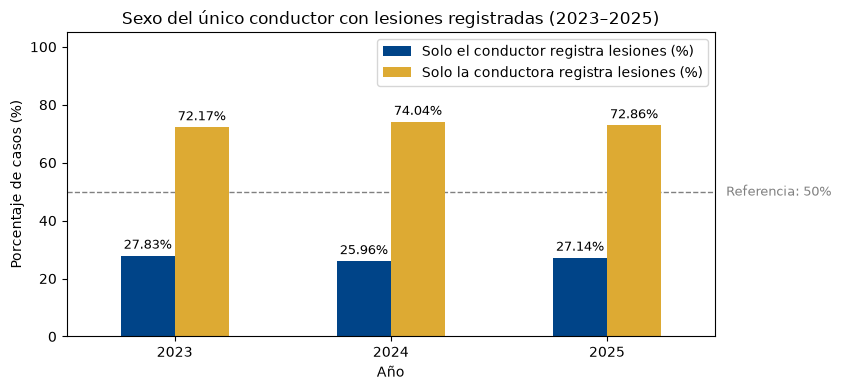

In [24]:
def graficar_un_lesionado(porcentajes):

    fig, ax = plt.subplots(figsize=(9, 4))

    porcentajes.set_index("Año").astype(float).plot.bar(
        ax=ax,
        color=["#004488", "#DDAA33"],
        rot=0
        )

    ax.axhline(
        y=50,
        color="gray",
        linestyle="--",
        linewidth=1,
        zorder=0,
        label="_nolegend_"
        )

    ax.annotate(
        "Referencia: 50%",
        xy=(1, 50),
        xycoords=("axes fraction", "data"),
        xytext=(8, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        color="gray",
        fontsize=9,
        annotation_clip=False
        )

    ax.set(
        title="Sexo del único conductor con lesiones registradas (2023–2025)",
        xlabel="Año",
        ylabel="Porcentaje de casos (%)"
        )

    ax.set_ylim(0, 105)

    ax.legend()

    for barras in ax.containers:
        ax.bar_label(barras, fmt="%.2f%%", padding=3, fontsize=9)

        fig.tight_layout()
        fig.subplots_adjust(right=0.80)

    plt.show()

graficar_un_lesionado(porcentajes_un_lesionado)

#### 4.2.2. Interpretación de resultados ####

Cuando solo uno de los conductores tiene lesiones registradas, se trata de la conductora en aproximadamente el 72% de los casos, durante los tres años de interés. Más específicamente:

- En 2023, la conductora fue la única con lesiones registradas en el 72.17% de los casos.

- En 2024, la conductora fue la única con lesiones registradas en el 74.04% de los casos.

- En 2025, la conductora fue la única con lesiones registradas en el 72.86% de los casos.


### 4.3. Siniestros con ambos conductores lesionados ###

En esta sección responderemos nuestra segunda conductora:

*¿Si ambos conductores presentan lesiones registradas de distinta gravedad, ¿hay una tendencia sobre quién presenta las más graves?*

#### 4.3.1. Cálculo de frecuencias relativas y absolutas ####

Para responder nuestra segunda pregunta conductora, seleccionaremos los siniestros en los que ambos conductores tienen lesiones registradas y compararemos sus categorías de gravedad. 

En un principio, distinguiremos tres casos: aquellos donde el hombre tiene lesiones más graves, aquellos donde la mujer tiene lesiones más graves y aquellos donde ambos tienen registrada la misma categoría de gravedad.

In [25]:
resumen = []

for año in análisis:

    vehículos = análisis[año]["vehicles"]

    def más_grave(collision_index: str) -> int:

        '''
        Recibe un identificador de siniestro y devuelve:

        1 si el hombre tiene lesiones más graves,

        2 si la mujer tiene lesiones más graves y

        0 si ambos tienen la misma gravedad.
        '''

        # Extraemos la pareja correspondiente con el identificador de siniestro (un DataFrame con dos filas)

        pareja = vehículos[vehículos["collision_index"] == collision_index]

        # Separamos los registros del conductor y de la conductora

        hombre = pareja[pareja["sex_of_driver"] == 1]

        mujer = pareja[pareja["sex_of_driver"] == 2]

        # Obtenemos las gravedades

        gravedad_hombre = hombre["casualty_severity"].iloc[0]

        gravedad_mujer = mujer["casualty_severity"].iloc[0]

        # ¡Ojo! La variable `casualty_severity` va de 1 a 3, donde 1 denota lesiones mortales, 2 denota lesiones graves y 3 denota lesiones leves

        # Es decir, números más bajos significan mayor gravedad

        if gravedad_hombre < gravedad_mujer:
            return 1

        elif gravedad_mujer < gravedad_hombre:
            return 2

        else:
            return 0

    # Seleccionamos los siniestros con ambos conductores lesionados.

    conductores_lesionados_por_siniestro = vehículos.groupby("collision_index")["casualty_severity"].count()

    siniestros_con_ambos_lesionados = conductores_lesionados_por_siniestro[conductores_lesionados_por_siniestro == 2
                                                                           ].index

    # Aplicamos la función a cada siniestro.

    resultados = pd.Series([más_grave(x) for x in siniestros_con_ambos_lesionados])

    # Contamos los resultados de las comparaciones.

    hombre = (resultados == 1).sum()
    mujer = (resultados == 2).sum()
    igual = (resultados == 0).sum()

    resumen.append({
        "Año": año,
        "Siniestros seleccionados (n)": len(análisis[año]["collisions"]),
        "Ambos lesionados (n)": len(siniestros_con_ambos_lesionados),
        "Distinta gravedad (n)": hombre + mujer,
        "Hombre más grave (n)": hombre,
        "Mujer más grave (n)": mujer,
        "Igual gravedad (n)": igual
    })

tabla_resumen = pd.DataFrame(resumen)

display(tabla_resumen)


,Año,Siniestros seleccionados (n),Ambos lesionados (n),Distinta gravedad (n),Hombre más grave (n),Mujer más grave (n),Igual gravedad (n)
0,2023,2202,742,205,80,125,537
1,2024,2197,771,232,93,139,539
2,2025,2078,703,214,89,125,489


Observamos que el tamaño de muestra con este filtro (ambos conductores lesionados, con distinta gravedad) es considerablemente menor que en el análisis anterior,debido a que, en la mayoría de los siniestros con ambos conductores lesionados, ambos tienen registrada la misma categoría de gravedad. Estos casos se excluyen de la comparación de quién presenta las lesiones más graves.

#### 4.3.2. Visualización de resultados ####

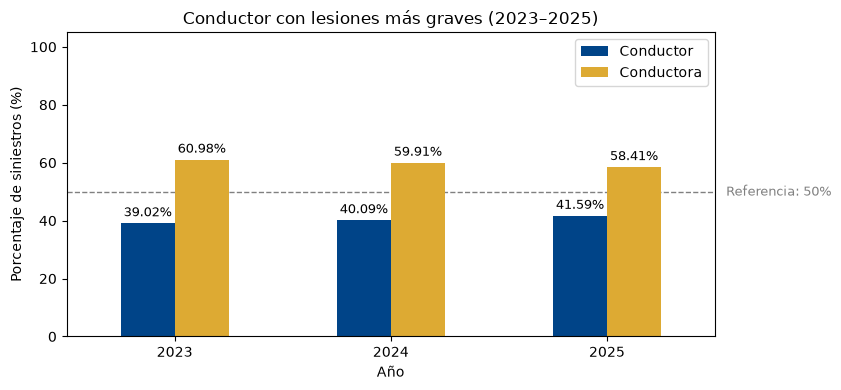

In [26]:
def graficar_gravedad():

    porcentajes_por_año = {}

    for año in [2023, 2024, 2025]:

        datos = tabla_resumen[tabla_resumen["Año"] == año].iloc[0]

        n = datos["Distinta gravedad (n)"]

        porcentajes = pd.Series({
            "Conductor": 100 * datos["Hombre más grave (n)"] / n,
            "Conductora": 100 * datos["Mujer más grave (n)"] / n
        })

        porcentajes_por_año[año] = porcentajes

    fig, ax = plt.subplots(figsize=(9, 4))

    pd.DataFrame(porcentajes_por_año).T.plot.bar(
        ax=ax,
        color=["#004488", "#DDAA33"],
        rot=0
    )

    ax.axhline(
        y=50,
        color="gray",
        linestyle="--",
        linewidth=1,
        zorder=0,
        label="_nolegend_"
    )

    ax.annotate(
        "Referencia: 50%",
        xy=(1, 50),
        xycoords=("axes fraction", "data"),
        xytext=(8, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        color="gray",
        fontsize=9,
        annotation_clip=False
    )

    ax.set(
        title="Conductor con lesiones más graves (2023–2025)",
        xlabel="Año",
        ylabel="Porcentaje de siniestros (%)"
    )

    ax.set_ylim(0, 105)
    ax.legend()

    for barras in ax.containers:
        ax.bar_label(barras, fmt="%.2f%%", padding=3, fontsize=9)

    fig.tight_layout()

    
    fig.subplots_adjust(right=0.80)

plt.show()

graficar_gravedad()

#### 4.3.3. Interpretación de resultados ####

Cuando ambos conductores tienen lesiones registradas con distinto nivel de gravedad, las conductoras concentran alrededor del 60% de los casos de mayor gravedad. Más específicamente:

- En 2023, entre todos los siniestros donde ambos tuvieron lesiones registradas de distinta gravedad, la mujer tenía las lesiones registradas más graves en el 60.98% de los casos.

- En 2024, entre todos los siniestros donde ambos tuvieron lesiones registradas de distinta gravedad, la mujer tenía las lesiones registradas más graves en el 59.91% de los casos.

- En 2025, entre todos los siniestros donde ambos tuvieron lesiones registradas de distinta gravedad, la mujer tenía las lesiones registradas más graves en el 58.41% de los casos.

Los resultados son consistentes con las observaciones de la pregunta 1. A su vez, estos datos mantienen una estabilidad anual.

## 5. Extensión del análisis: relación entre la cilindrada y las lesiones registradas ##

En la sección 4 respondimos nuestras dos preguntas conductoras principales. Como complemento exploratorio—manteniendo estrictamente la **estructura emparejada** de nuestra población de estudio—, en esta sección incorporamos una variable numérica adicional disponible en `vehicles`: la **cilindrada del motor (`engine_capacity_cc`)** medida en centímetros cúbicos (cc).

En la sección 1.4.2 advertimos que STATS19 no registra la masa de los vehículos y que la categoría `vehicle_type == 9` agrupa desde autos subcompactos hasta camionetas SUV. Aunque la cilindrada del motor no equivale exactamente al peso del automóvil, suele asociarse con el tamaño y segmento de la unidad.

En particular, la tabla `vehicles` incluye la variable `engine_capacity_cc`, que registra la cilindrada de cada vehículo medida en centímetros cúbicos (cc). Si bien la cilindrada de un motor no equivale exactamente al peso del automóvil, suele asociarse con el tamaño y segmento de la unidad, por lo que será de nuestro interés investigar relaciones que emergen al considerar esta variable.

Cabe mencionar que, según lo declarado en la documentación oficial de STATS19, el código `-1` se utiliza para denotar valores faltantes o fuera de rango. 

### 5.1. Planteamiento del problema ###

En los siniestros de nuestra población donde ambos vehículos cuentan con una cilindrada válida registrada, podemos calcular la diferencia

$$ \Delta_{\text{cc}} = \text{cc}_{\text{hombre}} - \text{cc}_{\text{mujer}}$$

donde $\text{cc}_{\text{hombre}}$ y $\text{cc}_{\text{mujer}}$ denotan las cilindradas de los vehículos conducidos por el hombre y por la mujer, respectivamente. Observamos que si ambas cilindradas coinciden, entonces la diferencia es cero, mientras que:

- La diferencia entre cilindradas $\Delta_{\text{cc}}$ es **positiva**, si el hombre conducía el vehículo con la mayor cilindrada.

- La diferencia entre cilindradas $\Delta_{\text{cc}}$ es **negativa**, si la mujer conducía el vehículo con la mayor cilindrada.

A partir de esto, formulamos las siguientes dos preguntas exploratorias complementarias:

*Primera pregunta.* Dentro de nuestra población emparejada, ¿cómo se distribuye la diferencia de cilindrada dentro de cada pareja según cuál de los dos conductores es el único con lesiones registradas?

*Segunda pregunta.* Si ponemos condiciones sobre la cilindrada, ¿hay cambios en el porcentaje de siniestros donde la mujer fue la única con lesiones registradas? Por ejemplo, si ponemos como condición que las cilindradas de los vehículos no difieran mucho entre sí, ¿se reduce el porcentaje de siniestros en los que la mujer fue la única con lesiones registradas?

#### 5.1.1. Consideraciones sobre automóviles eléctricos ####

Recordemos que la categoría `vehicle_type == 9` consiste en cualquier tipo de automóvil, lo cual puede incluir vehículos eléctricos. Como un automóvil eléctrico, por definición, no tiene cilindrada, es oportuno tomar esto en cuenta para el desarrollo de nuestro análisis complementario.

Afortunadamente, STATS19 registra el tipo de propulsión de un vehículo en la variable `propulsion_code` de la tabla `vehicles`. Según lo documentado en guía oficial de decodificación de variables de STATS19, los vehículos eléctricos reciben el código `3` en dicha variable, así que usaremos esta información para descartar los pares de automóviles en los que alguno de ellos está registrado como un vehículo eléctrico.

### 5.2. Incorporación de variables complementarias ###

Para responder las preguntas conductoras principales de nuestro proyecto, trabajamos con el diccionario `análisis` que incluía la información de la población de siniestros que estábamos considerando. 

El objetivo de esta sección es definir un nuevo diccionario, `análisis_cilindradas`, cuyos datos incluyan las variables `engine_capacity_cc`, para poder explorar nuestras preguntas complementarias, y `propulsion_code`, para eliminar los registros de siniestros en donde participó algún automóvil eléctrico:

In [27]:
variables_complementarias = ["propulsion_code", "engine_capacity_cc"]

In [28]:
análisis_cilindradas = {}

for año, datos_anuales in análisis.items():

    # Creamos un diccionario para el año correspondiente.

    análisis_cilindradas[año] = {}

    # Copiamos cada una de las tres tablas.

    for nombre, tabla in datos_anuales.items():

        análisis_cilindradas[año][nombre] = tabla.copy()

# Incorporamos las dos variables a la tabla de vehículos, para cada año

    análisis_cilindradas[año]["vehicles"] = análisis_cilindradas[año]["vehicles"].merge(
        datos[año]["vehicles"][
            ["collision_index", 
             "vehicle_reference"] + variables_complementarias],
        on=["collision_index", 
            "vehicle_reference"],
        how="left",
        validate="one_to_one"
    )


### 5.3. Calidad y limpieza de datos. ###

#### 5.3.1. Auditoría de calidad de `engine_capacity_cc` ####

Antes de calcular medidas de tendencia central o dispersión, verificamos que `engine_capacity_cc` esté presente en los tres años y auditamos posibles problemas de calidad: valores nulos estándar (`NaN`), código `-1` (dato faltante o fuera de rango), valores de `0` cc y posibles valores extremos (menores de 500 cc o mayores de 8,000 cc para un automóvil).

También comparamos las estadísticas descriptivas calculadas antes y después de excluir los valores no positivos.

In [29]:
auditoría_cc = []

for año in análisis_cilindradas:

    vehículos = análisis_cilindradas[año]["vehicles"]

    # Auditamos nulos, códigos especiales (-1 y 0) y posibles valores atípicos

    cc = vehículos["engine_capacity_cc"]
    n_total = len(cc)
    n_nan = int(cc.isna().sum())
    n_menos_uno = int((cc == -1).sum())
    n_otros_negativos = int((cc < -1).sum())
    n_cero = int((cc == 0).sum())
    n_bajo = int(((cc > 0) & (cc < 500)).sum())
    n_alto = int((cc > 8000).sum())

    # Comparamos la media antes y después de excluir valores no positivos

    cc_positivos = cc.where(cc > 0, np.nan)
    media_antes = round(cc.mean(), 2)
    media_después = round(cc_positivos.mean(), 2) if cc_positivos.notna().any() else np.nan
    desv_después = round(cc_positivos.std(), 2) if cc_positivos.notna().any() else np.nan

    auditoría_cc.append({
        "Año": año,
        "Vehículos (n)": n_total,
        "NaN estándar": n_nan,
        "Código -1 (n)": n_menos_uno,
        # "Código -1 (%)": round(100 * n_menos_uno / n_total, 2),
        "Valor 0 cc (n)": n_cero,
        "Otros negativos (n)": n_otros_negativos,
        "Cilindradas <500 cc": n_bajo,
        "Cilindradas >8000 cc": n_alto,
        "Media ANTES (con -1 y 0)": media_antes,
        "Media DESPUÉS (>0)": media_después,
        "Desv. Est. (>0)": desv_después
    })

tabla_auditoría_cc = pd.DataFrame(auditoría_cc)
display(tabla_auditoría_cc)

,Año,Vehículos (n),NaN estándar,Código -1 (n),Valor 0 cc (n),Otros negativos (n),Cilindradas <500 cc,Cilindradas >8000 cc,Media ANTES (con -1 y 0),Media DESPUÉS (>0),Desv. Est. (>0)
0,2023,4404,0,377,0,0,1,0,1479.53,1618.14,514.12
1,2024,4394,0,659,0,0,2,0,1337.12,1573.21,469.43
2,2025,4156,0,388,0,0,0,0,1445.64,1594.60,488.58


#### 5.3.2. Auditoría de cilindrada en automóviles eléctricos ####

El objetivo de esta sección es detectar posibles inconsistencias entre ambas variables, es decir, examinaremos qué valores de `engine_capacity_cc` aparecen en los vehículos identificados mediante `propulsion_code == 3` (eléctricos).

In [30]:
auditoría_eléctricos = []

for año in análisis_cilindradas:

    vehículos = análisis_cilindradas[año]["vehicles"]

    # Seleccionamos los vehículos eléctricos.

    eléctricos = vehículos[vehículos["propulsion_code"] == 3]

    # Auditamos sus valores de cilindrada.

    cc = eléctricos["engine_capacity_cc"]

    n_total = len(cc)
    n_nan = int(cc.isna().sum())
    n_menos_uno = int((cc == -1).sum())
    n_cero = int((cc == 0).sum())
    n_positivos = int((cc > 0).sum())
    n_otros_negativos = int((cc < -1).sum())

    auditoría_eléctricos.append({
        "Año": año,
        "Eléctricos (n)": n_total,
        "NaN (n)": n_nan,
        "Código -1 (n)": n_menos_uno,
        "Valor 0 cc (n)": n_cero,
        "Cilindrada positiva (n)": n_positivos,
        "Otros negativos (n)": n_otros_negativos
    })

tabla_auditoría_eléctricos = pd.DataFrame(auditoría_eléctricos)

display(tabla_auditoría_eléctricos)

,Año,Eléctricos (n),NaN (n),Código -1 (n),Valor 0 cc (n),Cilindrada positiva (n),Otros negativos (n)
0,2023,73,0,73,0,0,0
1,2024,108,0,107,0,1,0
2,2025,171,0,166,0,5,0


#### 5.3.3. Exclusión de siniestros con automóviles eléctricos

El siguiente código crea el diccionario `análisis_sin_eléctricos`, a partir de `análisis_cilindradas`, excluyendo las parejas completas de los siniestros en los que participó algún automóvil registrado como eléctrico. De esta manera, conservamos intactos los datos utilizados en las auditorías anteriores.

In [31]:
resumen = {}

análisis_sin_eléctricos = {}

for año in análisis_cilindradas:

    vehículos = análisis_cilindradas[año]["vehicles"]

    # Identificamos los siniestros con vehículos eléctricos

    eléctricos = vehículos.loc[vehículos["propulsion_code"] == 3]

    siniestros_a_descartar = eléctricos.groupby("collision_index").size()

    # Contamos las parejas descartadas

    resumen[año] = len(siniestros_a_descartar)

    análisis_sin_eléctricos[año] = {}

    # Descartamos las parejas completas de las tres tablas

    for nombre in análisis_cilindradas[año]:

        tabla = análisis_cilindradas[año][nombre]

        análisis_sin_eléctricos[año][nombre] = tabla.loc[
            tabla["collision_index"].isin(siniestros_a_descartar.index) == False
        ].copy()

display(pd.DataFrame.from_dict(
    resumen,
    orient="index",
    columns=["Parejas descartadas"]
))

,Parejas descartadas
2023,73
2024,104
2025,168


#### 5.3.4. Limpieza de cilindradas y verificación de la población resultante ####

**Problema.** En `engine_capacity_cc`, algunos datos faltantes o fuera de rango aparecen codificados con `-1` (lo cual sesga hacia abajo cualquier promedio y distorsiona la desviación estándar si se trata como una cilindrada real). Asimismo, pueden presentarse valores de `0` cc y valores extremos que requieren revisión. Además, para respetar la estructura por pares de nuestro estudio, no conviene promediar hombres y mujeres en dos conjuntos separados, sino comparar ambos automóviles *dentro del mismo siniestro*.

**Cómo lo abordamos (criterio estadístico).**

1. **Recodificación sin imputación.** Después de excluir los siniestros con automóviles eléctricos, consideramos válidas únicamente las cilindradas comprendidas entre 500 y 8,000 cc, reemplazando los valores fuera de este intervalo por `np.nan`. 

   Adoptamos este intervalo como un criterio operativo de limpieza para reducir la presencia de posibles errores de registro. Decidimos **no imputar** los faltantes porque asignar una cilindrada promedio artificial distorsionaría la diferencia real dentro de cada pareja.

2. **Transformación a tabla por pares (1 fila = 1 siniestro).** Reorganizamos los datos para que cada fila represente un siniestro completo con las columnas `cc_hombre`, `cc_mujer`, el desenlace de lesiones y la **diferencia emparejada** $\Delta_{\text{cc}} = \text{cc}_{\text{hombre}} - \text{cc}_{\text{mujer}}$ (valores positivos indican que el hombre conducía el automóvil de mayor cilindrada; valores negativos, que la mujer conducía el automóvil de mayor cilindrada).

**Consecuencias para nuestros datos y resultados.** Únicamente los siniestros donde **ambos** automóviles cuentan con cilindrada válida entran en el cálculo de $\Delta_{\text{cc}}$ (sin afectar los conteos ni los resultados de la sección 4). 

A continuación documentamos cuántos pares válidos se conservan por año, calculamos las medidas de tendencia central, dispersión (desviación estándar) y posición ($Q_1$, mediana, $Q_3$ e $IQR$), y estratificamos los siniestros con un solo conductor con lesiones registradas según quién conducía el automóvil de mayor cilindrada.

In [32]:
pares_lista = []
disponibilidad_pares = []

for año in análisis_sin_eléctricos:

    df = análisis_sin_eléctricos[año]["vehicles"].copy()

    # Reemplazamos las cilindradas fuera del intervalo válido por NaN

    df["cc_limpia"] = df["engine_capacity_cc"].where(
    df["engine_capacity_cc"].between(500, 8000), np.nan
)

    # Separamos los registros del conductor (hombre) y de la conductora (mujer)

    hombres = df[df["sex_of_driver"] == 1][
        ["collision_index", "cc_limpia", "lesión_registrada", "casualty_severity"]
    ].rename(columns={
        "cc_limpia": "cc_hombre",
        "lesión_registrada": "lesión_hombre",
        "casualty_severity": "gravedad_hombre"
    })

    mujeres = df[df["sex_of_driver"] == 2][
        ["collision_index", "cc_limpia", "lesión_registrada", "casualty_severity"]
    ].rename(columns={
        "cc_limpia": "cc_mujer",
        "lesión_registrada": "lesión_mujer",
        "casualty_severity": "gravedad_mujer"
    })

    # Unimos ambos conductores del mismo siniestro en una sola fila (1 fila = 1 par)

    pares = hombres.merge(
        mujeres,
        on="collision_index",
        how="inner",
        validate="one_to_one"
    )

    pares["Año"] = año

    # Clasificamos el desenlace de lesiones de cada siniestro emparejado

    condiciones = [
        (pares["lesión_hombre"]) & (~pares["lesión_mujer"]),
        (~pares["lesión_hombre"]) & (pares["lesión_mujer"]),
        (pares["lesión_hombre"]) & (pares["lesión_mujer"])
    ]

    etiquetas = [
        "Solo hombre lesionado",
        "Solo mujer lesionada",
        "Ambos lesionados"
    ]

    pares["desenlace"] = np.select(
        condiciones,
        etiquetas,
        default="Ningún conductor lesionado"
    )

    # Calculamos la diferencia de cilindrada dentro de cada pareja (hombre menos mujer)

    pares["dif_cc"] = pares["cc_hombre"] - pares["cc_mujer"]

    # Registramos la disponibilidad anual de pares con ambas cilindradas válidas

    n_pares = len(pares)
    n_válidos = int(pares["dif_cc"].notna().sum())

    disponibilidad_pares.append({
        "Año": año,
        "Siniestros emparejados (n)": n_pares,
        "Pares con ambas cilindradas válidas (n)": n_válidos,
        "% disponible": round(100 * n_válidos / n_pares, 2)
    })

    pares_lista.append(pares)

# Consolidamos todos los pares del periodo y conservamos los que tienen ambas cilindradas válidas

pares_cc_todos = pd.concat(pares_lista, ignore_index=True)

pares_cc_válidos = pares_cc_todos[
    pares_cc_todos["dif_cc"].notna()
].copy()

# Detectamos automáticamente qué años aportaron pares válidos para etiquetar tablas y gráficas

años_con_datos = sorted(pares_cc_válidos["Año"].unique().tolist())

etiqueta_años = (
    f"{años_con_datos[0]}–{años_con_datos[-1]}"
    if len(años_con_datos) > 1
    else f"{años_con_datos[0]}"
)

print("Disponibilidad de pares con cilindrada válida en ambos automóviles:")

tabla_disponibilidad = pd.DataFrame(disponibilidad_pares)

display(tabla_disponibilidad)

Disponibilidad de pares con cilindrada válida en ambos automóviles:


,Año,Siniestros emparejados (n),Pares con ambas cilindradas válidas (n),% disponible
0,2023,2129,1852,86.99
1,2024,2093,1626,77.69
2,2025,1910,1709,89.48


**Calidad y muestra.** Excluir los valores no positivos de `engine_capacity_cc` (el código `-1` estaba presente en entre el 8.6 % y el 15.0 % de los vehículos por año) produjo diferencias de hasta 236 cc en las medias anuales calculadas. Después de aplicar los criterios de limpieza y exclusión de automóviles eléctricos, se analizaron **5,187 pares** con cilindrada válida en ambos automóviles (80.08 % de la población emparejada de 2023–2025). 

Esta reducción debe considerarse al interpretar los resultados, pues la disponibilidad de cilindradas válidas podría estar relacionada con características de los vehículos o de los siniestros. Por tanto, no podemos asegurar que los siniestros excluidos tengan las mismas características que los conservados.

Para interpretar visualmente los resultados de este análisis, construimos dos figuras:

1. *Diagrama de violín con diagrama de caja superpuesto.* Muestra la distribución, los cuartiles y la media de la diferencia emparejada $\Delta_{\text{cc}}$ según cuál de los dos conductores es el único con lesiones registradas (sección 5.4.2).

2. *Gráfico de barras agrupadas.* Muestra los porcentajes de siniestros en los que solo el conductor o solo la conductora tiene lesiones registradas, según la diferencia de cilindrada entre ambos automóviles (sección 5.5.2).

### 5.4. Distribución de las diferencias de cilindrada según el desenlace de lesiones

#### 5.4.1. Estadística descriptiva 

In [33]:
# Función auxiliar para calcular medidas de tendencia central, dispersión y posición

def resumir_variable(serie, nombre):
    return {
        "Grupo / Variable": nombre,
        "Pares (n)": int(serie.count()),
        "Media (cc)": round(serie.mean(), 2),
        "Desv. Estándar (cc)": round(serie.std(), 2),
        "Mediana (cc)": round(serie.median(), 2),
        "Q1 (cc)": round(serie.quantile(0.25), 2),
        "Q3 (cc)": round(serie.quantile(0.75), 2),
        "IQR (cc)": round(serie.quantile(0.75) - serie.quantile(0.25), 2),
    }

# Calculamos los estadísticos generales y los de la diferencia emparejada Δcc por desenlace

filas_estadísticos = [
    resumir_variable(pares_cc_válidos["cc_hombre"], "Cilindrada auto del hombre (global)"),
    resumir_variable(pares_cc_válidos["cc_mujer"], "Cilindrada auto de la mujer (global)"),
    resumir_variable(pares_cc_válidos["dif_cc"], "Diferencia Δcc = hombre − mujer (global)"),
]

for grupo in ["Solo hombre lesionado", "Solo mujer lesionada", "Ambos lesionados"]:
    sub = pares_cc_válidos.loc[pares_cc_válidos["desenlace"] == grupo, "dif_cc"]
    if len(sub) > 0:
        filas_estadísticos.append(resumir_variable(sub, f"Δcc | {grupo}"))

tabla_estadísticos_cc = pd.DataFrame(filas_estadísticos)
tabla_estadísticos_cc.to_csv("resultados/anexo_estadisticos_cilindrada.csv", index=False)

print(f"Medidas de tendencia central, dispersión y posición ({etiqueta_años}):")
display(tabla_estadísticos_cc)

Medidas de tendencia central, dispersión y posición (2023–2025):


,Grupo / Variable,Pares (n),Media (cc),Desv. Estándar (cc),Mediana (cc),Q1 (cc),Q3 (cc),IQR (cc)
0,Cilindrada auto del hombre (global),5187,1692.01,540.39,1597.0,1360.0,1984.0,624.0
1,Cilindrada auto de la mujer (global),5187,1507.46,430.34,1461.0,1200.0,1600.0,400.0
2,Diferencia Δcc = hombre − mujer (global),5187,184.54,686.79,165.0,-201.5,571.0,772.5
3,Δcc | Solo hombre lesionado,791,1.79,702.02,0.0,-396.0,444.0,840.0
4,Δcc | Solo mujer lesionada,2115,292.55,676.02,236.0,-99.0,609.0,708.0
5,Δcc | Ambos lesionados,1803,146.64,672.70,100.0,-243.0,508.0,751.0


#### 5.4.2. Visualización ####

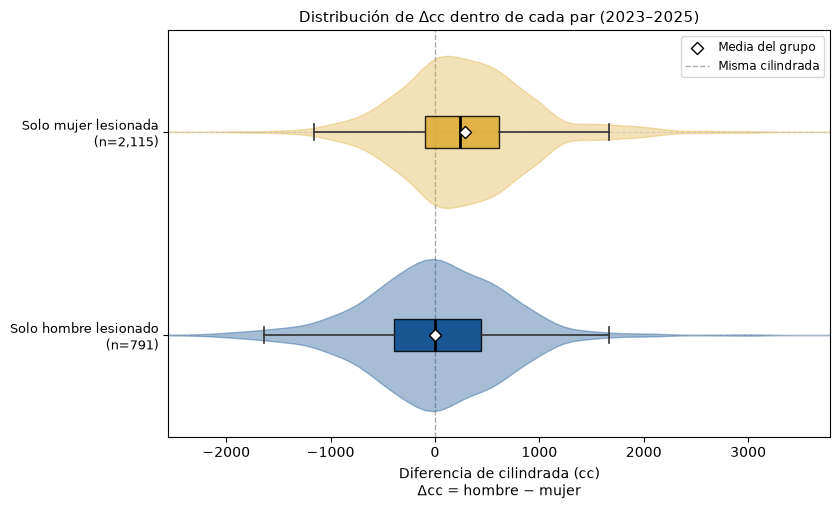

In [34]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))

# Diagrama de violín + boxplot de la diferencia emparejada Δcc 

#grupos_orden = [
#    ("Solo hombre lesionado", "Solo hombre lesionado", "#004488"),
#    ("Solo mujer lesionada", "Solo mujer lesionada", "#DDAA33"),
#    ("Ambos lesionados", "Ambos lesionados", "#668899"),
#]
grupos_orden = [
    ("Solo hombre lesionado", "Solo hombre lesionado", "#004488"),
    ("Solo mujer lesionada", "Solo mujer lesionada", "#DDAA33"),
]


datos_violín = []
etiquetas_violín = []
colores_violín = []

for clave, etiq, col in grupos_orden:
    serie = pares_cc_válidos.loc[pares_cc_válidos["desenlace"] == clave, "dif_cc"].dropna()
    if len(serie) > 0:
        datos_violín.append(serie.values)
        etiquetas_violín.append(f"{etiq}\n(n={len(serie):,})")
        colores_violín.append(col)

posiciones = np.arange(1, len(datos_violín) + 1)

# Graficamos los violines para visualizar la densidad completa de Δcc

vp = ax.violinplot(
    datos_violín,
    positions=posiciones,
    widths=0.75,
    showmeans=False,
    showmedians=False,
    showextrema=False,
    orientation="horizontal"
)

for cuerpo, color in zip(vp["bodies"], colores_violín):
    cuerpo.set_facecolor(color)
    cuerpo.set_edgecolor(color)
    cuerpo.set_alpha(0.35)

# Superponemos un boxplot estilizado para destacar Q1, mediana y Q3

bp = ax.boxplot(
    datos_violín,
    positions=posiciones,
    widths=0.16,
    patch_artist=True,
    showfliers=False,
    orientation="horizontal",
    medianprops=dict(color="black", linewidth=2.0),
    whiskerprops=dict(color="#333333", linewidth=1.2),
    capprops=dict(color="#333333", linewidth=1.2)
)

for caja, color in zip(bp["boxes"], colores_violín):
    caja.set_facecolor(color)
    caja.set_alpha(0.85)

# Señalamos la media de cada grupo con un rombo blanco

medias = [np.mean(d) for d in datos_violín]
ax.scatter(
    medias,
    posiciones,
    marker="D",
    color="white",
    edgecolor="black",
    s=38,
    zorder=5,
    label="Media del grupo"
)

# Línea de referencia en 0 (misma cilindrada en ambos autos)

ax.axvline(0, color="#888888", linestyle="--", linewidth=1, alpha=0.7, zorder=0, label="Misma cilindrada")

# Ajustamos el eje horizontal al rango central para reducir el efecto visual de los valores extremos

y_inf, y_sup = pares_cc_válidos["dif_cc"].quantile([0.005, 0.995])
margen_y = (y_sup - y_inf) * 0.18
ax.set_xlim(y_inf - margen_y, y_sup + margen_y * 1.35)

ax.set_yticks(posiciones)
ax.set_yticklabels(etiquetas_violín, fontsize=9)
ax.set_xlabel("Diferencia de cilindrada (cc)\nΔcc = hombre − mujer")
ax.set_title(f"Distribución de Δcc dentro de cada par ({etiqueta_años})", fontsize=10.5)
ax.legend(loc="upper right", frameon=True, fontsize=8.5)
ax.grid(axis="y", linestyle="--", alpha=0.45)


fig.tight_layout()
plt.show()

#### 5.4.3. Interpretación de resultados ####


En el caso de siniestros en donde solo el conductor resultó lesionado, las diferencias de cilindradas presentan una media cercana a cero (1.79 cc) y una mediana de cero.

Por otro lado, en el caso de los siniestros en los que solo la conductora resultó lesionada, la distribución de las diferencias de cilindradas está ligeramente desplazada hacia la derecha; es decir, hacia valores positivos de $\Delta_{\text{cc}}$, que asociamos con cilindradas más grandes por parte del conductor.

### 5.5. Relación entre la diferencia de cilindradas y el sexo del único conductor lesionado ###

#### 5.5.1. Comparación de porcentajes según la diferencia de cilindradas

Para estudiar la relación entre las diferencias de cilindrada y las lesiones registradas, clasificaremos los siniestros en tres grupos: 

1. Aquellos donde el automóvil del hombre tiene una cilindrada superior en más de 100 cc.

2. Aquellos donde la diferencia absoluta de cilindradas es menor o igual a 100 cc.

3. Aquellos donde el automóvil de la mujer tiene una cilindrada superior en más de 100 cc.

Cabe mencionar que el umbral de 100 cc constituye un criterio exploratorio de agrupación y no garantiza condiciones físicas equivalentes entre los automóviles.

In [35]:
# En siniestros con exactamente un conductor lesionado, clasificamos quién tenía mayor cilindrada

pares_uno = pares_cc_válidos[
    pares_cc_válidos["desenlace"].isin(["Solo hombre lesionado", "Solo mujer lesionada"])
].copy()

cond_ventaja = [
    pares_uno["dif_cc"] > 100,
    pares_uno["dif_cc"].abs() <= 100,
    pares_uno["dif_cc"] < -100
]
etiq_ventaja = [
    "Cilindrada del hombre > mujer (>100 cc)",
    "Cilindradas similares (|Δcc| ≤ 100 cc)",
    "Cilindrada de la mujer > hombre (>100 cc)"
]
pares_uno["ventaja_motor"] = np.select(cond_ventaja, etiq_ventaja, default="Otro")

filas_ventaja = []
for cat in etiq_ventaja:
    sub = pares_uno[pares_uno["ventaja_motor"] == cat]
    n_cat = len(sub)
    n_hom = int((sub["desenlace"] == "Solo hombre lesionado").sum())
    n_muj = int((sub["desenlace"] == "Solo mujer lesionada").sum())
    if n_cat > 0:
        filas_ventaja.append({
            "Comparación de motores dentro del par": cat,
            "Siniestros (n)": n_cat,
            "Solo hombre (n)": n_hom,
            "Solo mujer (n)": n_muj,
            "Solo hombre (%)": round(100 * n_hom / n_cat, 2),
            "Solo mujer (%)": round(100 * n_muj / n_cat, 2),
        })

tabla_ventaja_motor = pd.DataFrame(filas_ventaja)
tabla_ventaja_motor.to_csv("resultados/anexo_lesion_por_ventaja_motor.csv", index=False)

print(f"\nPorcentaje de lesión única según diferencia de cilindrada dentro del par ({etiqueta_años}):")
display(tabla_ventaja_motor)


Porcentaje de lesión única según diferencia de cilindrada dentro del par (2023–2025):


,Comparación de motores dentro del par,Siniestros (n),Solo hombre (n),Solo mujer (n),Solo hombre (%),Solo mujer (%)
0,Cilindrada del hombre > mujer (>100 cc),1613,334,1279,20.71,79.29
1,Cilindradas similares (|Δcc| ≤ 100 cc),448,129,319,28.79,71.21
2,Cilindrada de la mujer > hombre (>100 cc),845,328,517,38.82,61.18


#### 5.5.2. Visualización de resultados

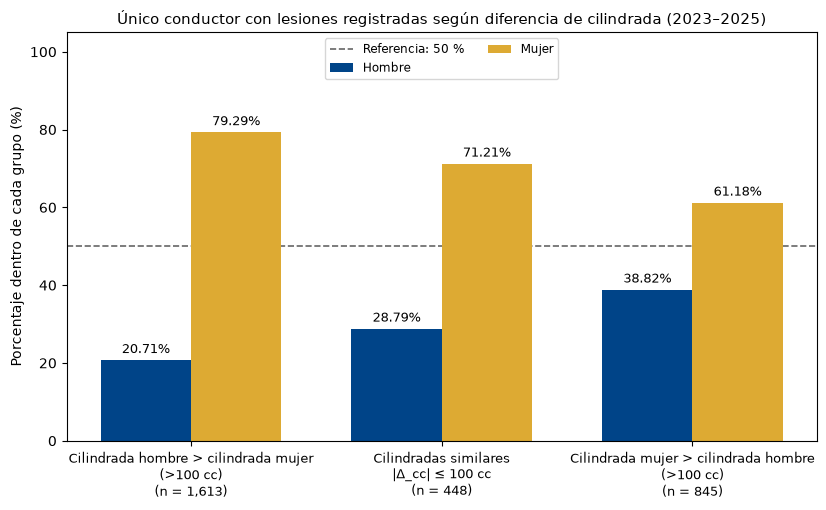

In [36]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))

etiquetas_cortas = [
    f"Cilindrada hombre > cilindrada mujer\n(>100 cc)\n(n = {int(row['Siniestros (n)']):,})"
    if "hombre >" in row["Comparación de motores dentro del par"]
    else (
        f"Cilindradas similares\n|Δ_cc| ≤ 100 cc\n(n = {int(row['Siniestros (n)']):,})"
        if "similares" in row["Comparación de motores dentro del par"]
        else f"Cilindrada mujer > cilindrada hombre\n(>100 cc)\n(n = {int(row['Siniestros (n)']):,})"
    )
    for _, row in tabla_ventaja_motor.iterrows()
]

x_bar = np.arange(len(tabla_ventaja_motor))
ancho = 0.36

b1 = ax.bar(
    x_bar - ancho / 2,
    tabla_ventaja_motor["Solo hombre (%)"],
    width=ancho,
    color="#004488",
    label="Hombre"
)
b2 = ax.bar(
    x_bar + ancho / 2,
    tabla_ventaja_motor["Solo mujer (%)"],
    width=ancho,
    color="#DDAA33",
    label="Mujer"
)

ax.set_axisbelow(True)
ax.axhline(50, color="#666666", linestyle="--", linewidth=1.2, zorder=0, label="Referencia: 50 %")
ax.set_xticks(x_bar)
ax.set_xticklabels(etiquetas_cortas, fontsize=9)
ax.set_ylim(0, 105)
ax.set_ylabel("Porcentaje dentro de cada grupo (%)")
ax.set_title(
    f"Único conductor con lesiones registradas según diferencia de cilindrada ({etiqueta_años})",
    fontsize=10.5
)
ax.legend(loc="upper center", ncol=2, frameon=True, fontsize=8.5)
ax.bar_label(b1, fmt="%.2f%%", padding=3, fontsize=9)
ax.bar_label(b2, fmt="%.2f%%", padding=3, fontsize=9)

fig.tight_layout()
plt.savefig("resultados/anexo_fig2_diferencia_cilindrada.png", dpi=300, bbox_inches="tight")
plt.show()

#### 5.5.3. Interpretación de resultados

Para esta comparación consideramos únicamente los siniestros con ambas cilindradas válidas en los que exactamente uno de los dos conductores presentó lesiones registradas. Los porcentajes se calcularon dentro de cada grupo de diferencia de cilindrada, tomando como denominador el número de siniestros pertenecientes a ese grupo.

- En el primer grupo, el automóvil conducido por el hombre tiene una cilindrada superior a la del automóvil conducido por la mujer en más de 100 cc. 
   
    De los 1,613 siniestros que cumplen esta condición, en el 79.29 % únicamente la conductora presentó lesiones registradas, mientras que en el 20.71 % únicamente las presentó el conductor.

- En el segundo grupo, la diferencia absoluta entre las cilindradas de ambos automóviles es menor o igual a 100 cc. 
   
    De los 448 siniestros que cumplen esta condición, en el 71.21 % únicamente la conductora presentó lesiones registradas, mientras que en el 28.79 % únicamente las presentó el conductor.

- En el tercer grupo, el automóvil conducido por la mujer tiene una cilindrada superior a la del automóvil conducido por el hombre en más de 100 cc. 
   
    De los 845 siniestros que cumplen esta condición, en el 61.18% únicamente la conductora presentó lesiones registradas, mientras que en el 38.82 % únicamente las presentó el conductor.

El porcentaje de siniestros en los que únicamente la conductora presenta lesiones registradas disminuye **18.11 puntos porcentuales** entre los grupos extremos: pasa del 79.29% cuando el automóvil del hombre tiene una cilindrada superior en más de 100 cc al 61.18% cuando el automóvil de la mujer tiene una cilindrada superior en más de 100 cc. Sin embargo, incluso en este último grupo, las conductoras siguen concentrando la mayoría de los casos con lesiones registradas únicamente en uno de los dos conductores.

Estos resultados muestran una asociación entre la diferencia de cilindrada dentro de cada pareja y la distribución por sexo del único conductor con lesiones registradas, pero no permiten determinar qué parte de las diferencias observadas se explica por la cilindrada.


---

## 6. Conclusiones ##

### 6.1. Resultados principales

A partir del análisis descriptivo de los registros oficiales de STATS19 (para 2023, 2024 y 2025), enfocado en siniestros de exactamente dos automóviles, conducidos por un hombre y una mujer, en los que ambos vehículos registraron el frente como primer punto de impacto, se obtuvieron dos resultados principales, que posteriormente complementamos con un análisis exploratorio de cilindrada:

1. **Respecto a la primera pregunta conductora.**

   Cuando solo uno de los dos conductores registra lesiones, *más del 72% de los casos corresponden a la conductora* en los tres años analizados (72.17% en 2023, 74.04% en 2024 y 72.86% en 2025), frente a un porcentaje en conductores hombres de entre el 25.96% y el 27.83%.

2. **Respecto a la segunda pregunta conductora.**

   Cuando ambos conductores tienen lesiones registradas pero con distinta severidad, *alrededor del 60% de los casos de mayor gravedad corresponden a la conductora* (60.98% en 2023, 59.91% en 2024 y 58.41% en 2025).

3. **Respecto al análisis complementario de cilindradas.**

   Observamos diferencias en la proporción de siniestros donde la conductora fue la única de los dos conductores con lesiones registradas, según cuál de los dos automóviles tenía mayor cilindrada. Esta proporción fue del 79.29 % cuando el automóvil del hombre tenía una cilindrada superior en más de 100 cc y del 61.18 % cuando ocurría lo contrario. La diferencia entre ambos grupos fue de 18.11 puntos porcentuales.


### 6.2. Alcances y limitaciones


#### 6.2.1. Lo que permiten concluir los resultados ####

En los siniestros de nuestra población de estudio, encontramos diferencias marcadas y relativamente estables entre hombres y mujeres en dos desenlaces:
  
  - El sexo del único conductor con lesiones registradas (cuando exactamente uno de los dos tiene lesiones registradas).
  
  - El sexo del conductor con lesiones de mayor gravedad, cuando ambos tienen lesiones registradas y estas son de distinta gravedad.

En ambos análisis, las conductoras aparecen con mayor frecuencia que los conductores hombres en el desenlace estudiado.

Por otro lado, el análisis complementario de cilindradas muestra una asociación entre la diferencia de cilindrada de los automóviles dentro de cada pareja y el sexo del único conductor con lesiones registradas.

#### 6.2.2. Lo que no permiten concluir los resultados ####

Nuestro análisis es de carácter exclusivamente exploratorio y **no pretende demostrar una relación causal** entre ninguna de las variables observadas.

En particular, nuestro análisis no permite establecer, por ejemplo, una relación causal  entre el sexo de un conductor y la propensión a presentar lesiones registradas (de mayor o menor gravedad) en un siniestro de dos automóviles.

De entrada, es importante recordar que en STATS19 solo se registran siniestros viales que:

1. Llegaron a conocimiento de las fuerzas policiales

2. Dejaron algún tipo de víctima.

3. Sucedieron en la vía pública.

De esta manera, los datos registrados en STATS19 **no representan** la totalidad de los siniestros de tránsito ocurridos en Gran Bretaña. 

Por otro lado, recordemos que según el Departamento de Transporte del Reino Unido existe un subregistro de víctimas de siniestros de tránsito en STATS19, especialmente en aquellos que involucran lesiones leves. Así pues, debemos tener presente que la ausencia de un conductor en `casualties` no garantiza que no haya sufrido lesiones en el siniestro correspondiente (una limitación que debe considerarse al interpretar los resultados de nuestras preguntas principales).

Otra dimensión a considerar es que, incluso en el universo de siniestros contemplados por STATS19, las tablas no recopilan todas las variables posibles que podrían explicar, total o parcialmente, la diferencia observada en nuestros resultados. Por ejemplo, STATS19 no proporciona información sobre la masa de los automóviles involucrados.

Lo anterior es particularmente importante para nuestras preguntas centrales, pues si existe una diferencia sistemática en el tamaño o masa promedio de los automóviles conducidos por mujeres y hombres, esto podría influir en los datos que analizamos en la sección 4 de este proyecto.

Finalmente, en cuanto al análisis con cilindradas, debemos tener en cuenta que la cilindrada es solo un indicador indirecto e imperfecto de características del automóvil, como su tamaño o masa, y presenta alta dispersión caso por caso. 

### 6.3. Líneas futuras de análisis

En módulos posteriores del diplomado, este trabajo puede extenderse mediante pruebas de hipótesis formales para proporciones emparejadas (como la prueba de McNemar), modelos de regresión logística condicional por siniestro y el cruce con bases vehiculares externas que incorporen la masa y clasificación de seguridad de cada unidad.